In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
data_path =r'D:\HVIA\task2\Sharnouby_Enterprise'

In [4]:
path =os.path.join(data_path, 'Product_Master.csv')

In [5]:
df_product_master = pd.read_csv(path)
df_product_master.head()

,Product_ID,SKU,Product_Name,Brand,Product_Family,Gender,Audience,Catalog_Season,Sizes,Public_Retail_Price_EGP,Public_Catalog_Source,Verification_Class
0,P001,26115-8,Summer children's girls-Happy,Leo Moda,Pajamas/Homewear,Girls,Kids,Summer 2026,"4, 6, 8, 10, 12",348,https://leo.moda/shop/,Public catalog product / public retail price
1,P002,26115-6,Summer children's girls-turtle,Leo Moda,Pajamas/Homewear,Girls,Kids,Summer 2026,"4, 6, 8, 10, 12",348,https://leo.moda/shop/,Public catalog product / public retail price
2,P003,26115-5,Summer children's girls-Hello kitty Rose & tur...,Leo Moda,Pajamas/Homewear,Girls,Kids,Summer 2026,"4, 6, 8, 10, 12",348,https://leo.moda/shop/,Public catalog product / public retail price
3,P004,26115-7,Summer children's girls-Hello kitty black&white,Leo Moda,Pajamas/Homewear,Girls,Kids,Summer 2026,"4, 6, 8, 10, 12",348,https://leo.moda/shop/,Public catalog product / public retail price
4,P005,26115-2,Summer children's boys-Black and orange,Leo Moda,Pajamas/Homewear,Boys,Kids,Summer 2026,"4, 6, 8, 10, 12",348,https://leo.moda/shop/,Public catalog product / public retail price


In [6]:
df_product_master.shape

(59, 12)

In [7]:
# numner of unique products
df_product_master['Product_ID'].nunique()

59

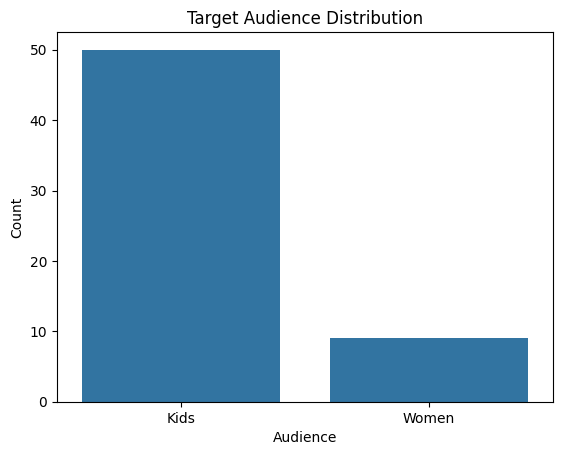

In [8]:
# target audience
sns.countplot(x='Audience', data=df_product_master)
plt.title('Target Audience Distribution')
plt.xlabel('Audience')
plt.ylabel('Count')
plt.show()

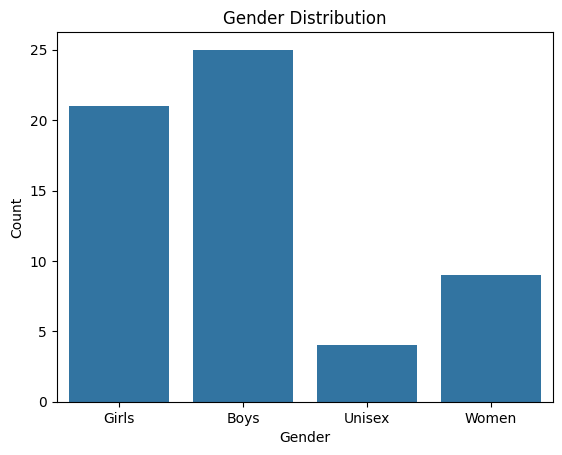

In [9]:
# distribution of gender
sns.countplot(x='Gender', data=df_product_master)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

<Axes: xlabel='Product_Family'>

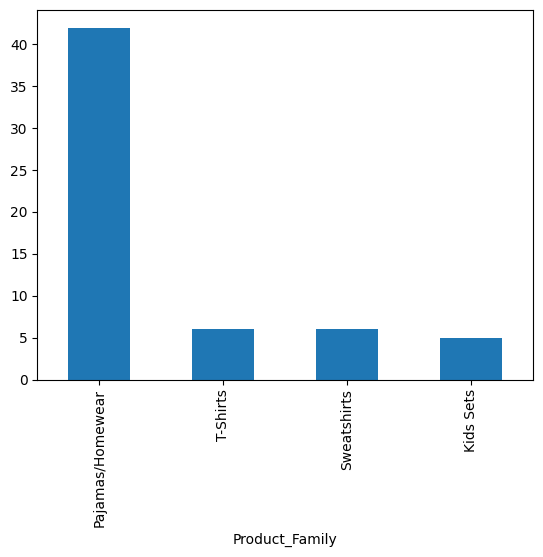

In [10]:
df_product_master['Product_Family'].value_counts().plot(kind='bar')

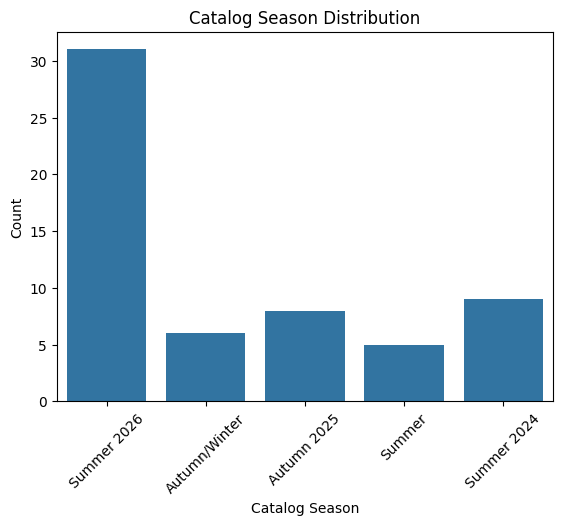

In [13]:
sns.countplot(x='Catalog_Season',  data=df_product_master)
plt.title('Catalog Season Distribution')
plt.xlabel('Catalog Season')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Text(0, 0.5, 'Count')

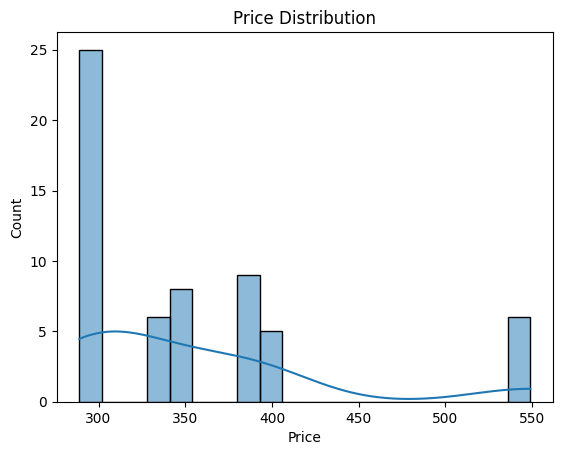

In [15]:
# distribution of price
sns.histplot(df_product_master['Public_Retail_Price_EGP'], bins=20, kde=True)
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')

In [17]:
agg_funcs = {
    "Public_Retail_Price_EGP": [
        "count",
        "min",
        "max",
        "median",
        "sum",
        "std"
    ]
}

# 1. Group by Gender
gender_stats = df_product_master.groupby("Gender").agg(agg_funcs)
display(gender_stats)

# 2. Group by Audience
audience_stats = df_product_master.groupby("Audience").agg(agg_funcs)
display(audience_stats)

# 3. Group by Catalog Season
season_stats = df_product_master.groupby("Catalog_Season").agg(agg_funcs)
display(season_stats)



Public_Retail_Price_EGP                                  
                         count  min  max median   sum        std
Gender                                                          
Boys                        25  289  549  330.0  8559  80.700000
Girls                       21  289  549  299.0  7274  89.612765
Unisex                       4  400  400  400.0  1600   0.000000
Women                        9  388  388  388.0  3492   0.000000

Public_Retail_Price_EGP                                   
                           count  min  max median    sum        std
Audience                                                           
Kids                          50  289  549  314.5  17433  81.885089
Women                          9  388  388  388.0   3492   0.000000

Public_Retail_Price_EGP                                  
                                 count  min  max median   sum        std
Catalog_Season                                                          
Autumn 2025                          8  289  289  289.0  2312   0.000000
Autumn/Winter                        6  549  549  549.0  3294   0.000000
Summer                               5  400  400  400.0  2000   0.000000
Summer 2024                          9  388  388  388.0  3492   0.000000
Summer 2026                         31  295  348  299.0  9827  22.368132

In [18]:
df_customers = pd.read_csv(os.path.join(data_path,'Customers.csv'))
df_customers.head()

,Customer_ID,Customer_Type,Governorate,Age_Band,Gender,Join_Date,Acquisition_Channel,Consent_Status,Data_Class
0,C00001,Retail,Dakahlia,45-54,Male,2026-02-22,Organic Social,Not opted-in,Modeled/anonymized training customer - not act...
1,C00002,Retail,Beheira,35-44,Male,2024-09-30,Direct / WhatsApp,Opted-in,Modeled/anonymized training customer - not act...
2,C00003,Retail,Dakahlia,25-34,Female,2025-06-27,Organic Social,Opted-in,Modeled/anonymized training customer - not act...
3,C00004,Wholesale,Port Said,Business,Business,2024-09-27,Wholesale Sales,Opted-in,Modeled/anonymized training customer - not act...
4,C00005,Retail,Gharbia,55+,Female,2025-02-07,Paid Social,Not opted-in,Modeled/anonymized training customer - not act...


In [19]:
# number of unique customers
df_customers['Customer_ID'].nunique()

30000

In [20]:
# customer distribution by Customer_Type
df_customers['Customer_Type'].value_counts()

Customer_Type
Retail       28349
Wholesale     1651
Name: count, dtype: int64

<Axes: ylabel='count'>

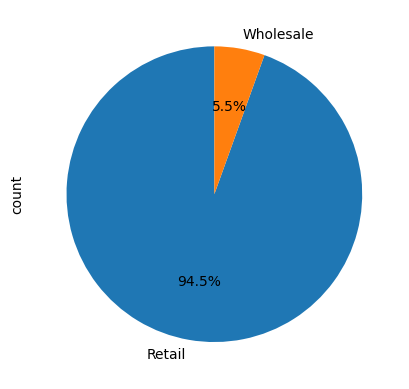

In [21]:
df_customers['Customer_Type'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)

In [22]:
df_customers['Governorate'].nunique()

13

<Axes: xlabel='count', ylabel='Governorate'>

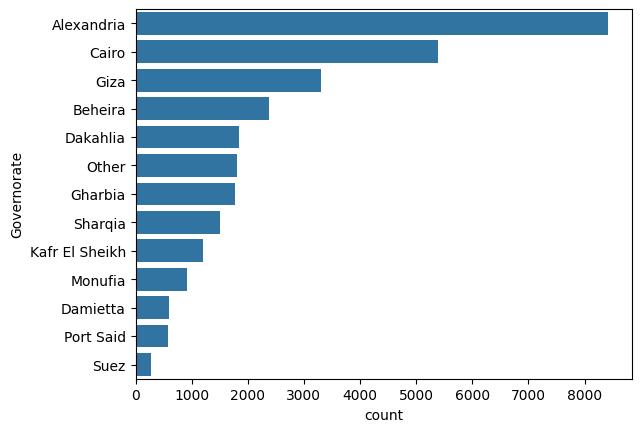

In [24]:
sns.countplot(y='Governorate', data=df_customers, order=df_customers['Governorate'].value_counts().index)

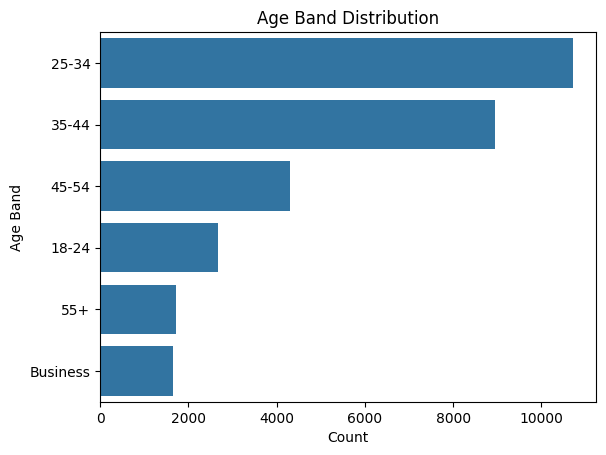

In [26]:
# distribution of Age_Band
sns.countplot(y='Age_Band', data=df_customers, order=df_customers['Age_Band'].value_counts().index)
plt.title('Age Band Distribution')
plt.xlabel('Count')
plt.ylabel('Age Band')
plt.show()

Text(0, 0.5, 'Count')

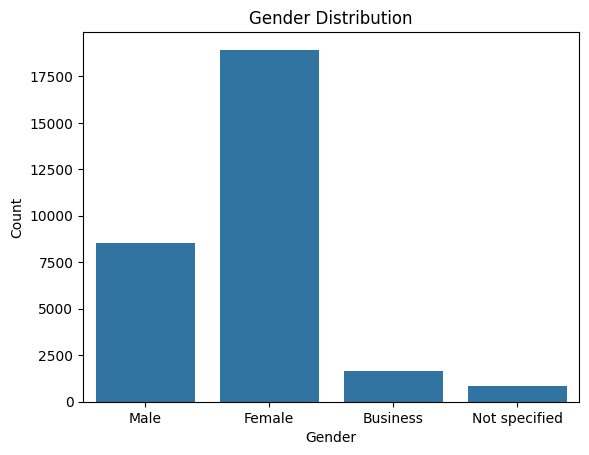

In [27]:
# distribution of Gender
sns.countplot(x='Gender', data=df_customers)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')

In [28]:
df_customers["Join_Date"] = pd.to_datetime(
    df_customers["Join_Date"], errors="coerce"
)

df_customers["Year"] = df_customers["Join_Date"].dt.year
df_customers["Month"] = df_customers["Join_Date"].dt.month
df_customers["Day"] = df_customers["Join_Date"].dt.day

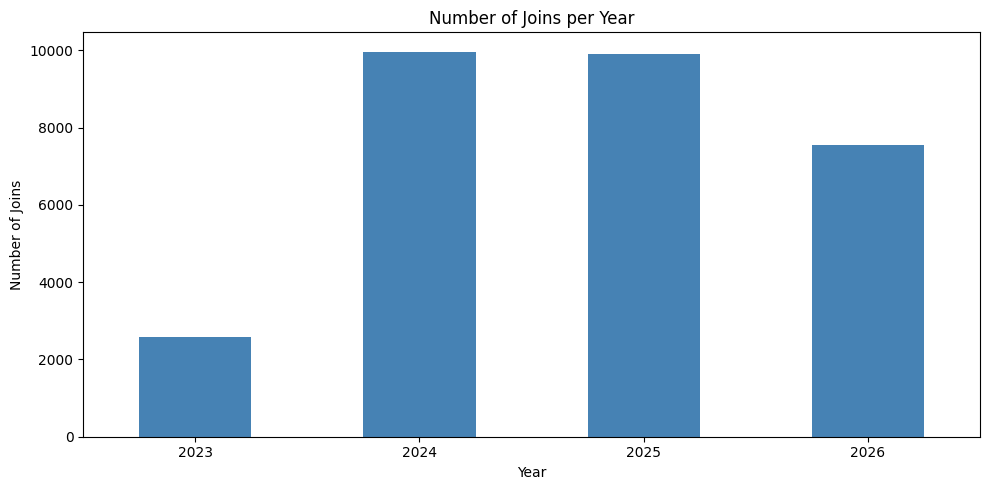

In [29]:
year_counts = df_customers.groupby("Year").size()

plt.figure(figsize=(10, 5))
year_counts.plot(kind="bar", color="steelblue")
plt.title("Number of Joins per Year")
plt.xlabel("Year")
plt.ylabel("Number of Joins")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

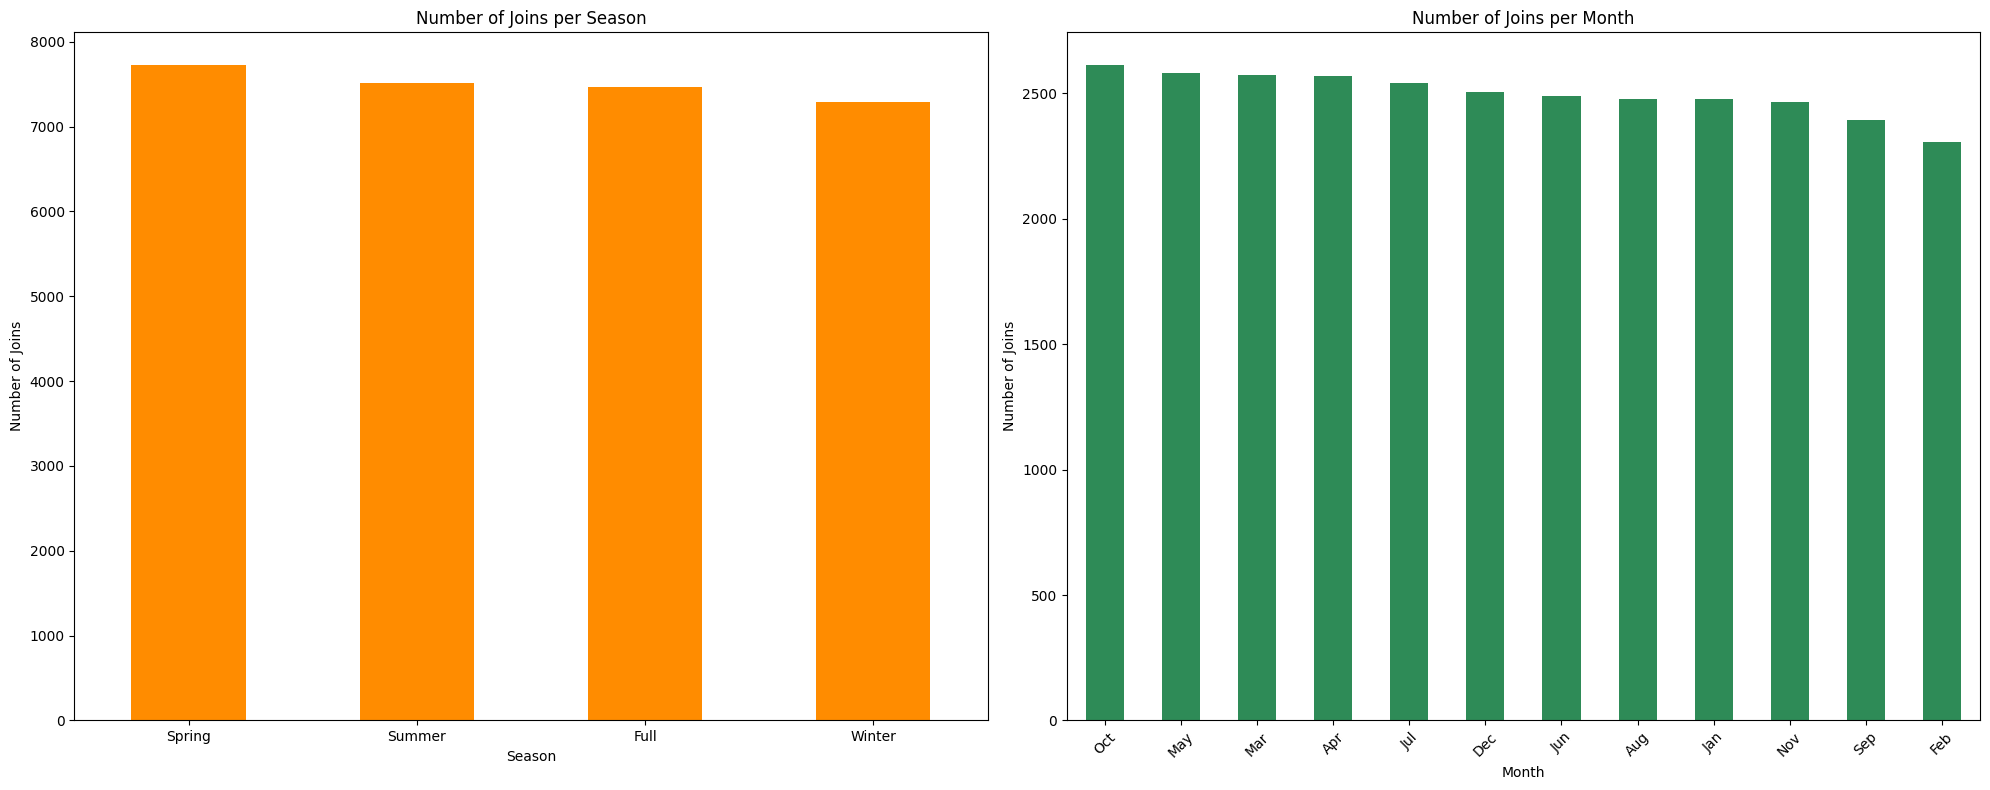

In [33]:
# Assign seasons based on your season categories
# Edit the month mapping if your business defines seasons differently
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Full", 10: "Full", 11: "Full"
}

df_customers["Season"] = df_customers["Month"].map(season_map)

season_order = ["Summer", "Winter", "Full", "Spring"]
month_order = list(range(1, 13))
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Season chart
# Season chart: highest count to lowest
season_counts = (
    df_customers["Season"]
    .value_counts()
    .sort_values(ascending=False)
)

season_counts.plot(kind="bar", ax=axes[0], color="darkorange")

axes[0].set_title("Number of Joins per Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Number of Joins")
axes[0].tick_params(axis="x", rotation=0)


# Month chart: highest count to lowest
month_counts = (
    df_customers["Month"]
    .value_counts()
    .rename(index=dict(enumerate(month_names, start=1)))
    .sort_values(ascending=False)
)

month_counts.plot(kind="bar", ax=axes[1], color="seagreen")

axes[1].set_title("Number of Joins per Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Joins")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

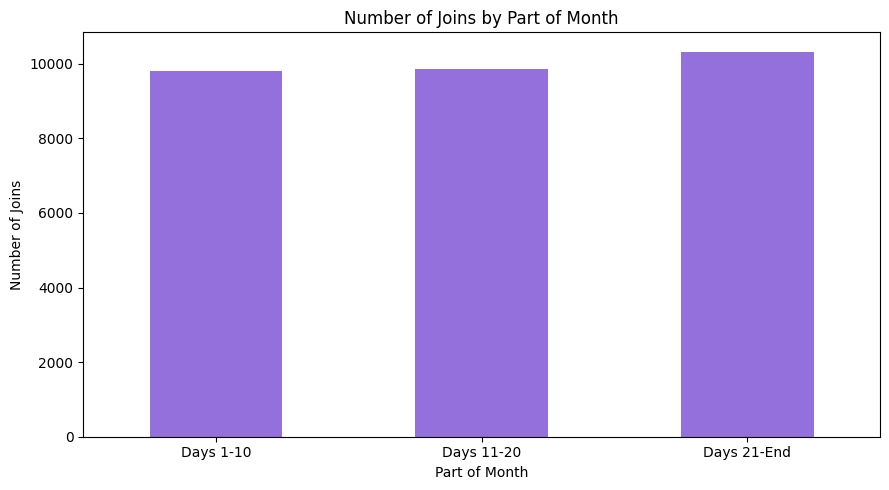

In [35]:
df_customers["Month_Part"] = pd.cut(
    df_customers["Day"],
    bins=[0, 10, 20, 31],
    labels=["Days 1-10", "Days 11-20", "Days 21-End"],
    include_lowest=True
)

part_counts = df_customers["Month_Part"].value_counts().reindex(
    ["Days 1-10", "Days 11-20", "Days 21-End"],
    fill_value=0
)

plt.figure(figsize=(9, 5))
part_counts.plot(kind="bar", color="mediumpurple")
plt.title("Number of Joins by Part of Month")
plt.xlabel("Part of Month")
plt.ylabel("Number of Joins")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

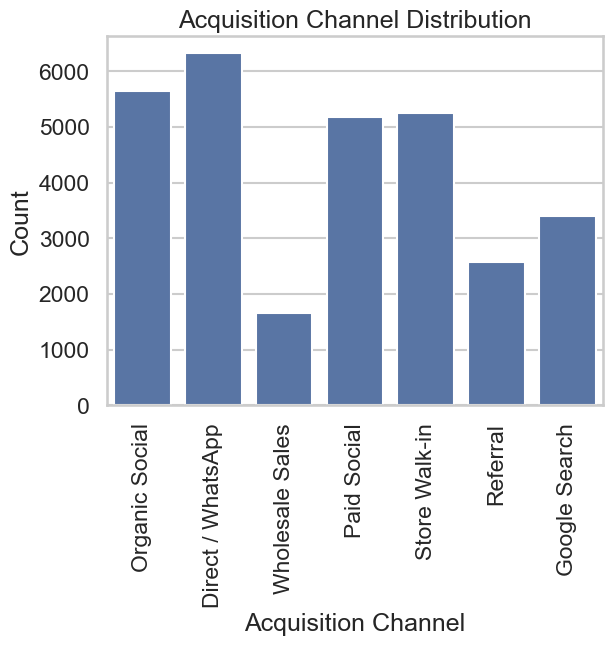

In [38]:
# distribution of Acquisition_Channel
sns.countplot(x='Acquisition_Channel', data=df_customers)
sns.set_theme(style="whitegrid")
sns.set_context("talk")
plt.title('Acquisition Channel Distribution')
plt.xlabel('Acquisition Channel')
plt.xticks(rotation=90)
plt.ylabel('Count')
plt.show()